In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv("data/lending_club_loan_two.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (396030, 27)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [3]:
# Separate input features and target
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (396030, 26)
Target shape: (396030,)

Target distribution:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


In [4]:


# First split: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# Second split: 20% validation, 20% test (keep test set aside)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (237618, 26)
Validation set: (79206, 26)
Test set: (79206, 26)


In [5]:
# Remove unnecessary high-cardinality columns
drop_cols = ["emp_title", "title", "address"]

X_train_reduced = X_train.drop(columns=drop_cols)
X_val_reduced = X_val.drop(columns=drop_cols)

# Identify numerical and categorical columns
num_cols = X_train_reduced.select_dtypes(include=np.number).columns
cat_cols = X_train_reduced.select_dtypes(exclude=np.number).columns

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ]
)

# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train_reduced)

# Transform validation data
X_val_processed = preprocessor.transform(X_val_reduced)

print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)

Training data shape: (237618, 872)
Validation data shape: (79206, 872)


In [6]:
depths = [1, 3, 5, 10, None]

train_accuracies = []
val_accuracies = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    train_pred = model.predict(X_train_processed)
    val_pred = model.predict(X_val_processed)

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Depth {depth}: Train Accuracy = {train_acc:.4f}, Validation Accuracy = {val_acc:.4f}")

Depth 1: Train Accuracy = 0.8039, Validation Accuracy = 0.8039
Depth 3: Train Accuracy = 0.8039, Validation Accuracy = 0.8039
Depth 5: Train Accuracy = 0.8054, Validation Accuracy = 0.8044
Depth 10: Train Accuracy = 0.8127, Validation Accuracy = 0.8004
Depth None: Train Accuracy = 1.0000, Validation Accuracy = 0.7255


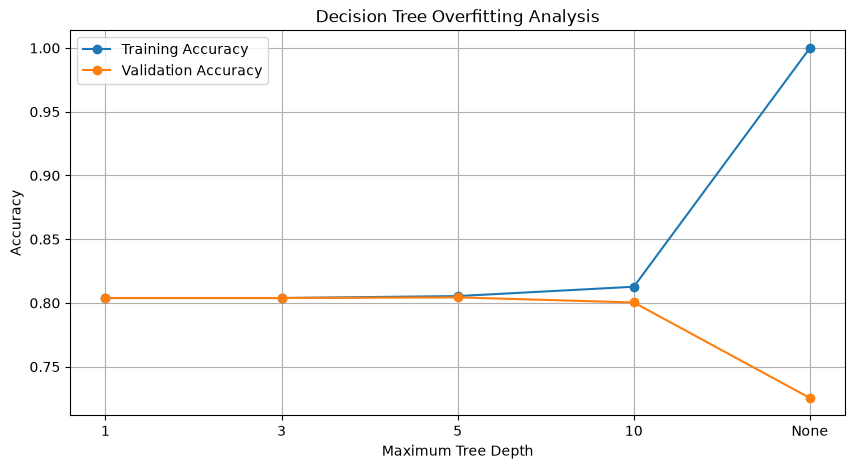

In [7]:

plt.figure(figsize=(10, 5))

plt.plot(
    ["1", "3", "5", "10", "None"],
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    ["1", "3", "5", "10", "None"],
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Overfitting Analysis")
plt.legend()
plt.grid(True)

plt.show()

In [8]:
# Create Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Keep preprocessing inside the Pipeline so each CV fold
# learns imputation and encoding only from its training fold.
cv_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", log_model)
])

# Perform 5-fold cross validation using the raw training features
cv_scores = cross_val_score(
    cv_pipeline,
    X_train_reduced,
    y_train,
    cv=5,
    scoring="accuracy"
)

# Display results
print("Cross Validation Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://s

Cross Validation Scores: [0.80357293 0.8032573  0.80344668 0.80316899 0.80394756]
Mean Accuracy: 0.8034786933614766
Standard Deviation: 0.00027374188109770834


In [9]:

# Select one numerical feature
X_demo = X[["loan_amnt"]]

# WRONG WAY: Scale the complete dataset before splitting
wrong_scaler = StandardScaler()
X_scaled_wrong = wrong_scaler.fit_transform(X_demo)

# Split after scaling
X_wrong_train, X_wrong_temp = train_test_split(
    X_scaled_wrong,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# CORRECT WAY: Split first
X_demo_train, X_demo_temp, y_demo_train, y_demo_temp = train_test_split(
    X_demo,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# Fit scaler only on training data
correct_scaler = StandardScaler()
X_correct_train = correct_scaler.fit_transform(X_demo_train)

# Transform remaining data without fitting again
X_correct_temp = correct_scaler.transform(X_demo_temp)

print("Wrong Scaling - Mean:", wrong_scaler.mean_[0])
print("Correct Scaling - Mean:", correct_scaler.mean_[0])

Wrong Scaling - Mean: 14113.888089286165
Correct Scaling - Mean: 14118.59255191105


### Explanation 

1. Wrong way: Scaling before splitting uses information from the entire dataset.
2. This includes validation and test data, causing data leakage.
3. Correct way: Split the dataset first and fit the scaler only on training data.
4. Use the same fitted scaler to transform validation and test data to prevent leakage.

## Classification of ML Problems

### 1. Spam Detection
- ML Type: Supervised Learning
- Reason: Emails are labelled as Spam or Not Spam.

### 2. Customer Segmentation
- ML Type: Unsupervised Learning
- Reason: Customers are grouped based on similar behaviour without predefined labels.

### 3. House Price Prediction
- ML Type: Supervised Learning
- Reason: The model learns from previous house prices to predict new prices.

### 4. Anomaly Detection
- ML Type: Unsupervised Learning
- Reason: Identifies unusual patterns without predefined labels.

---

## Machine Learning Workflow – 7 Steps

1. **Problem Definition:** Understand the problem and define the goal.

2. **Data Collection:** Collect relevant data from different sources.

3. **Data Preprocessing:** Handle missing values, duplicates, and incorrect data.

4. **Exploratory Data Analysis (EDA):** Analyze data using statistics and visualizations.

5. **Feature Engineering:** Select and transform useful features for the model.

6. **Model Training and Evaluation:** Train the ML model and evaluate its performance using suitable metrics.

7. **Deployment and Monitoring:** Deploy the model and monitor its performance regularly.